In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
import sys

import testis_model as tm

In [130]:
exp_scenario = 'full_pipeline'
model_simulations_path = os.path.join('..', 'model_simulations')

# Add to sys.path if not already present
if model_simulations_path not in sys.path:
    sys.path.append(model_simulations_path)
    print("Added to path:", model_simulations_path)
    
from saving_loading import find_scenarios, load_all_scenarios

scenarios_directory = os.path.join('..', 'model_simulations', 'scenarios')
fish_data, clone_data = load_all_scenarios(['full_pipeline', 'n1000_r3_y6_realistic'], directory = scenarios_directory)

fish_id = 14
fish = fish_data[exp_scenario, fish_id, 0]

In [131]:
import pandas as pd
import numpy as np

normalize = lambda x: x / np.sum(x)

# Group and compute normalized frequency vectors
freqs_series = (
    fish.groupby('time')
        .agg({'obs_result': tm.data_processing.add_tuples_elementwise})['obs_result']
        .apply(np.array)
        .apply(normalize)
)

# Convert to a DataFrame with two columns: time and frequency
freqs_over_time = pd.DataFrame({
    "time": freqs_series.index,
    "frequency": freqs_series.values
})

print(freqs_over_time.head())

   time                                          frequency
0  4.86  [0.6329411764705882, 0.10588235294117647, 0.09...
1  5.76  [0.3754152823920266, 0.0946843853820598, 0.181...
2  7.86  [0.0, 0.0, 0.2390745501285347, 0.1709511568123...
3  8.86  [0.0, 0.0, 0.2131455399061033, 0.2666666666666...
4  9.93  [0.0, 0.0, 0.1514114627887083, 0.2309666381522...


In [132]:
import numpy as np
from scipy.spatial.distance import euclidean, cityblock
from scipy.stats import entropy

def freq_distance(p, q, metric="l2", eps=1e-12):
    """
    - "l1" : L1 / total variation distance
    - "l2" : Euclidean distance
    - "hellinger" : Hellinger distance
    - "js" : Jensen–Shannon distance
    - "kl" : Kullback–Leibler divergence (not symmetric)
    """
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)

    # normalize to sum to 1
    p = p / p.sum()
    q = q / q.sum()

    if metric == "l1":
        return cityblock(p, q)  # sum |p - q|
    elif metric == "l2":
        return euclidean(p, q)
    elif metric == "hellinger":
        return np.linalg.norm(np.sqrt(p) - np.sqrt(q)) / np.sqrt(2)
    elif metric == "js":
        m = 0.5 * (p + q)
        return np.sqrt(0.5 * entropy(p, m) + 0.5 * entropy(q, m))
    elif metric == "kl":
        return entropy(p + eps, q + eps)  # KL(p || q)
    else:
        raise ValueError(f"Unknown metric: {metric}")

In [133]:
import numpy as np

# Assume freq_distance is already defined
# freqs_over_time has columns: "time" and "frequency"

freqs = freqs_over_time["frequency"].values  # array of numpy arrays

distances = np.empty(len(freqs))
distances[0] = np.nan  # no previous entry for the first row

for i in range(1, len(freqs)):
    distances[i] = freq_distance(freqs[i], freqs[i-1], metric="l2")  # choose metric here

# Attach back to DataFrame
freqs_over_time = freqs_over_time.copy()
freqs_over_time["distance_prev"] = distances

print(freqs_over_time.head())

   time                                          frequency  distance_prev
0  4.86  [0.6329411764705882, 0.10588235294117647, 0.09...            NaN
1  5.76  [0.3754152823920266, 0.0946843853820598, 0.181...       0.284249
2  7.86  [0.0, 0.0, 0.2390745501285347, 0.1709511568123...       0.465218
3  8.86  [0.0, 0.0, 0.2131455399061033, 0.2666666666666...       0.141446
4  9.93  [0.0, 0.0, 0.1514114627887083, 0.2309666381522...       0.088532


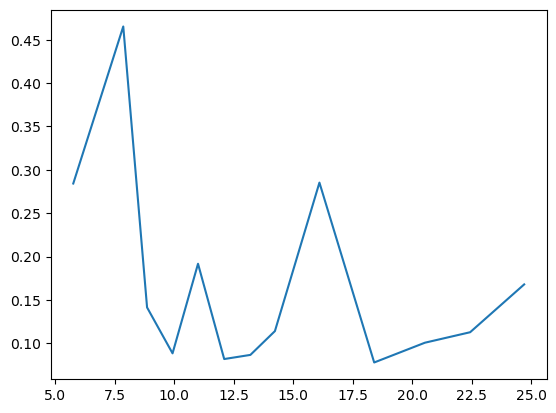

In [134]:
plt.plot(freqs_over_time['time'], freqs_over_time['distance_prev'])

In [95]:
import numpy as np
from scipy.stats import linregress

df = freqs_over_time[["time", "distance_prev"]].copy()
df_clean = df.dropna(subset=["distance_prev"])
t = df_clean["time"].values
d = df_clean["distance_prev"].values

In [96]:
result = linregress(t, d)

slope = result.slope
intercept = result.intercept
r_value = result.rvalue
p_value = result.pvalue

In [97]:
slope

np.float64(-0.01957880329596393)

In [113]:
rows = []
for (scenario, fish, duplicate), data in fish_data.items():
    freqs_series = (
        data.groupby('time')
            .agg({'obs_result': tm.data_processing.add_tuples_elementwise})['obs_result']
            .apply(np.array)
            .apply(normalize)
    )
    
    # Convert to a DataFrame with two columns: time and frequency
    freqs_over_time = pd.DataFrame({
        "time": freqs_series.index,
        "frequency": freqs_series.values
    })

    freqs = freqs_over_time["frequency"].values  # array of numpy arrays

    distances = np.empty(len(freqs))
    distances[0] = np.nan  # no previous entry for the first row
    
    for i in range(1, len(freqs)):
        distances[i] = freq_distance(freqs[i], freqs[i-1], metric="l2")  # choose metric here
    
    # Attach back to DataFrame
    freqs_over_time = freqs_over_time.copy()
    freqs_over_time["distance_prev"] = distances

    df = freqs_over_time[["time", "distance_prev"]].copy()
    df_clean = df.dropna(subset=["distance_prev"])
    t = df_clean["time"].values
    d = df_clean["distance_prev"].values

    result = linregress(t, d)

    slope = result.slope
    intercept = result.intercept
    r_value = result.rvalue
    p_value = result.pvalue

    row = dict()
    row['scenario'] = scenario
    row['fish'] = fish
    row['duplicate'] = duplicate
    row['slope'] = slope
    row['n_transient'] = data['time'].nunique()

    rows.append(row)

res = pd.DataFrame(rows)

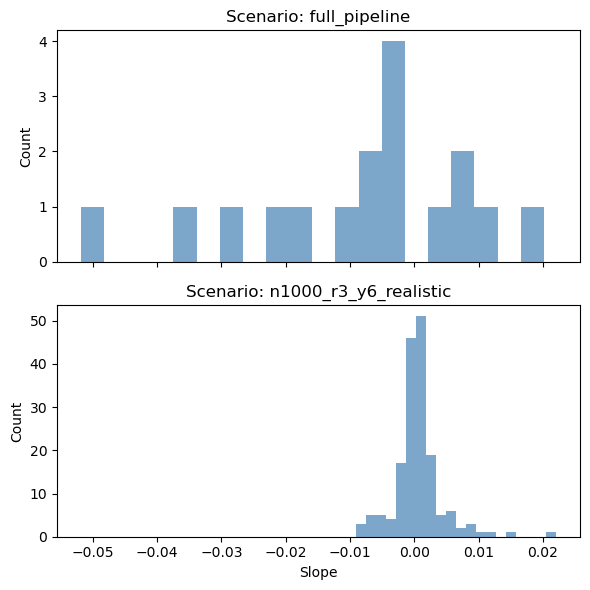

In [120]:
import matplotlib.pyplot as plt

res2 = res[res['n_transient'] > 6].copy()

# Ensure scenarios are treated as categories
scenarios = res['scenario'].unique()
n = len(scenarios)

fig, axes = plt.subplots(n, 1, figsize=(6, 3*n), sharex=True)

if n == 1:
    axes = [axes]  # ensure iterable

for ax, scenario in zip(axes, scenarios):
    subset = res2.loc[res2['scenario'] == scenario, 'slope'].dropna()
    ax.hist(subset, bins=20, alpha=0.7, color='steelblue')
    ax.set_title(f"Scenario: {scenario}")
    ax.set_ylabel("Count")

axes[-1].set_xlabel("Slope")
plt.tight_layout()
plt.show()

In [122]:
np.mean(res2.query('scenario == "n1000_r3_y6_realistic" and not slope.isna()')['slope'])

np.float64(0.0005921531042263201)

In [123]:
np.mean(res2.query('scenario == "full_pipeline" and not slope.isna()')['slope'])

np.float64(-0.008155777128075987)